In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 19.5 — Tensor categories

Source: SMSA 7.8, 2026-11-05, `smsa.pdf`. References below use section and equation numbers. Read the corresponding SMSA passage first. Native DisCoPy drawings run **top to bottom**: this preview reverses SMSA’s usual vertical flow while preserving left-to-right tensor order. A coupon replaces SMSA’s specialized glyph where necessary. This notebook uses no user-defined functions or assertion checks.

Equations (19.32)–(19.33): SMSA calls $Y$ a right dual and orders the maps as $1\to X\otimes Y$ and $Y\otimes X\to1$. The matching native type is `X.l`. Match domains and codomains before matching words such as “left” and “right”. Associators have identity images in the strict translation.

In [1]:
from discopy import rigid
X = rigid.Ty('X')
Y = X.l
coev = rigid.Cap(X, Y)
ev = rigid.Cup(Y, X)
snake_X = (coev @ rigid.Id(X)) >> (rigid.Id(X) @ ev)
snake_Y = (rigid.Id(Y) @ coev) >> (ev @ rigid.Id(Y))
for name, diagram, expected in [('X', snake_X, rigid.Id(X)), ('Y', snake_Y, rigid.Id(Y))]:
    print(name, 'actual boundary:', diagram.dom, '->', diagram.cod)
    print('Computed normal form:', diagram.normal_form())
    print('Expected:', expected)
    print('Equal:', diagram.normal_form() == expected)

X actual boundary: X -> X
Computed normal form: Id(X)
Expected: Id(X)
Equal: True
Y actual boundary: X.l -> X.l
Computed normal form: Id(X.l)
Expected: Id(X.l)
Equal: True


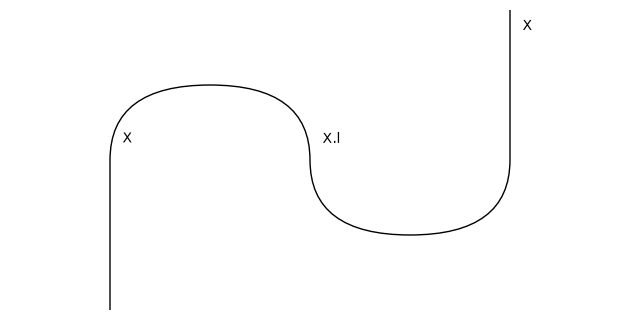

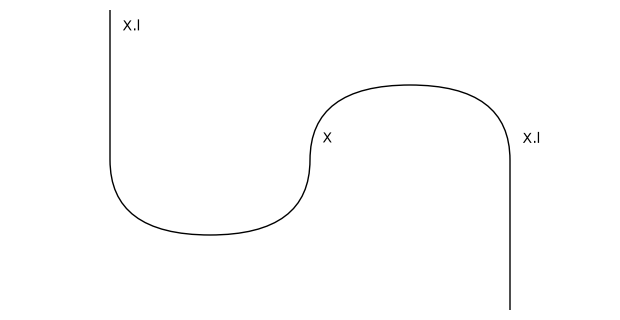

In [2]:
snake_X.draw(figsize=(6, 3))
snake_Y.draw(figsize=(6, 3))

For the opposite ordering (19.34)–(19.35), use `X.r`: the coevaluation outputs `X.r @ X` and the evaluation consumes `X @ X.r`.

19.35 X computed: Id(X) ; expected: Id(X)
Equal: True
19.35 left dual computed: Id(X.r) ; expected: Id(X.r)
Equal: True


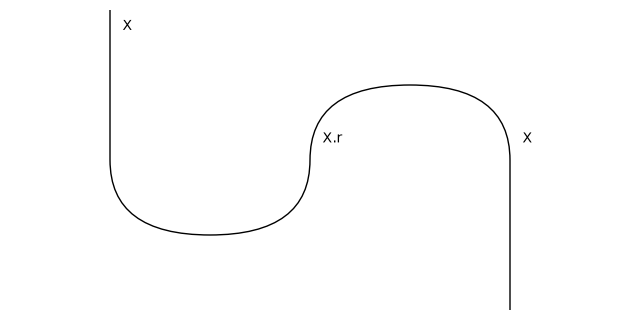

In [3]:
Z = X.r
left_coev = rigid.Cap(Z, X)
left_ev = rigid.Cup(X, Z)
left_snake_X = (rigid.Id(X) @ left_coev) >> (left_ev @ rigid.Id(X))
left_snake_Z = (left_coev @ rigid.Id(Z)) >> (rigid.Id(Z) @ left_ev)
for name, diagram, expected in [('X', left_snake_X, rigid.Id(X)), ('left dual', left_snake_Z, rigid.Id(Z))]:
    print('19.35', name, 'computed:', diagram.normal_form(), '; expected:', expected)
    print('Equal:', diagram.normal_form() == expected)
left_snake_X.draw(figsize=(6, 3))

The native rigid rewrite verifies the strict snake relation. Native bend arrows differ from SMSA’s glyphs; the printed dual labels preserve the distinction. Hopf-module structure is not evaluated here.